<a href="https://colab.research.google.com/github/Sifuna-E/spaceship-titanic-machine-learning/blob/main/spaceship_titanic_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Spaceship Titanic: Exploratory Data Analysis and Machine Learning.**


This project uses the Kaggle Spaceship Titanic dataset to investigate the factors associated with passengers being transported to another dimension. We apply exploratory data analysis, feature engineering and supervised machine-learning classification models to predict the binary outcome, Transported. Model performance is evaluated using accuracy.

SPACESHIP TITANIC: COMPLETE DATA ANALYSIS AND MODEL BUILDING

In [1]:

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

print("=" * 65)
print("SPACESHIP TITANIC MACHINE LEARNING PROJECT")
print("=" * 65)



SPACESHIP TITANIC MACHINE LEARNING PROJECT


1. LOAD THE DATA

In [2]:
required_files = [
    "train.csv",
    "test.csv",
    "sample_submission.csv"
]

missing_files = [f for f in required_files if not os.path.exists(f)]

if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}. "
        "Upload all three CSV files using the Colab Files panel."
    )

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("\n1. DATA LOADED SUCCESSFULLY")
print("Training data:", train.shape)
print("Test data:", test.shape)
print("Sample submission:", sample_submission.shape)


1. DATA LOADED SUCCESSFULLY
Training data: (8693, 14)
Test data: (4277, 13)
Sample submission: (4277, 2)


2. DATA INSPECTION

In [3]:
print("\n2. TRAINING DATA PREVIEW")
display(train.head())

print("\nDATA TYPES")
display(train.dtypes.to_frame("Data type"))

print("\nSUMMARY STATISTICS")
display(train.describe(include="all").T)

print("\nDUPLICATE ROWS:", train.duplicated().sum())
print("DUPLICATE PASSENGER IDs:", train["PassengerId"].duplicated().sum())


2. TRAINING DATA PREVIEW


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True



DATA TYPES


,Data type
PassengerId,object
HomePlanet,object
CryoSleep,object
Cabin,object
Destination,object
Age,float64
VIP,object
RoomService,float64
FoodCourt,float64
ShoppingMall,float64



SUMMARY STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,8693,8693,0001_01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HomePlanet,8492,3,Earth,4602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CryoSleep,8476,2,False,5439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cabin,8494,6560,G/734/S,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,8511,3,TRAPPIST-1e,5915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,8514.0,NaN,NaN,NaN,28.82793,14.489021,0.0,19.0,27.0,38.0,79.0
VIP,8490,2,False,8291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RoomService,8512.0,NaN,NaN,NaN,224.687617,666.717663,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,NaN,NaN,NaN,458.077203,1611.48924,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,NaN,NaN,NaN,173.729169,604.696458,0.0,0.0,0.0,27.0,23492.0



DUPLICATE ROWS: 0
DUPLICATE PASSENGER IDs: 0


3. TARGET VARIABLE ANALYSIS


3. TARGET VARIABLE DISTRIBUTION


,Count,Percentage
Transported,,
True,4378,50.36
False,4315,49.64


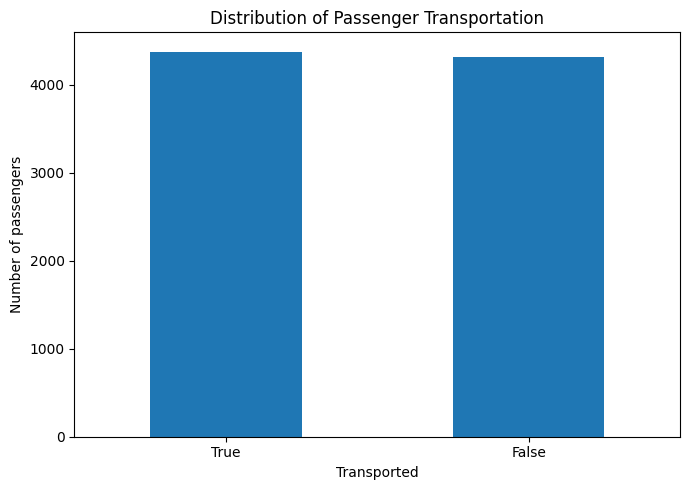

In [4]:
print("\n3. TARGET VARIABLE DISTRIBUTION")

target_counts = train["Transported"].value_counts()
target_percentages = train["Transported"].value_counts(normalize=True) * 100

display(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
}))

plt.figure(figsize=(7, 5))
train["Transported"].value_counts().plot(
    kind="bar", rot=0
)
plt.title("Distribution of Passenger Transportation")
plt.xlabel("Transported")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()


4. MISSING VALUE ANALYSIS


4. MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage
CryoSleep,217,2.50
ShoppingMall,208,2.39
VIP,203,2.34
HomePlanet,201,2.31
Name,200,2.30
Cabin,199,2.29
VRDeck,188,2.16
Spa,183,2.11
FoodCourt,183,2.11
Destination,182,2.09


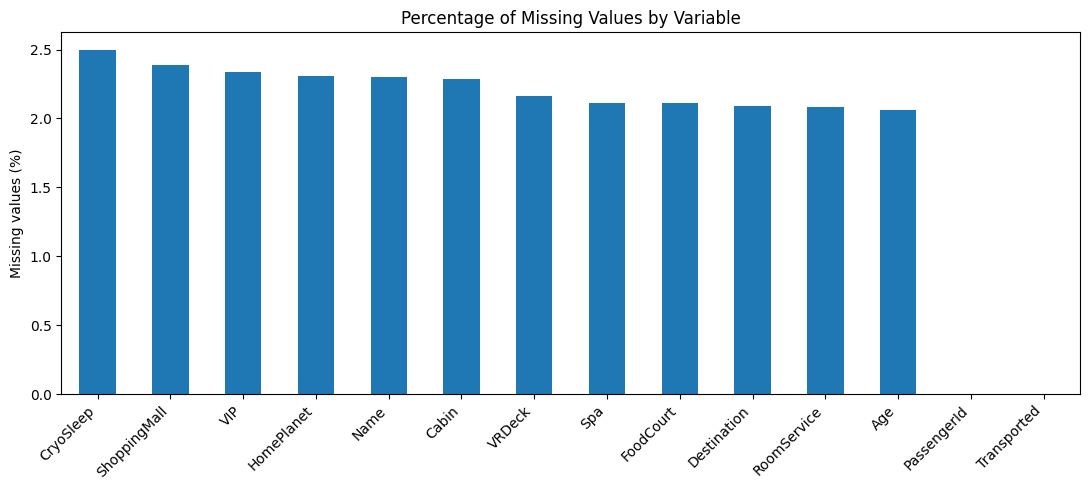

In [5]:
print("\n4. MISSING VALUE ANALYSIS")

missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": (
        train.isnull().mean() * 100
    ).round(2)
})

missing = missing.sort_values(
    "Missing Percentage", ascending=False
)

display(missing)

plt.figure(figsize=(11, 5))
missing["Missing Percentage"].plot(kind="bar")
plt.title("Percentage of Missing Values by Variable")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

5. EXPLORATORY DATA ANALYSIS


5. EXPLORATORY DATA ANALYSIS


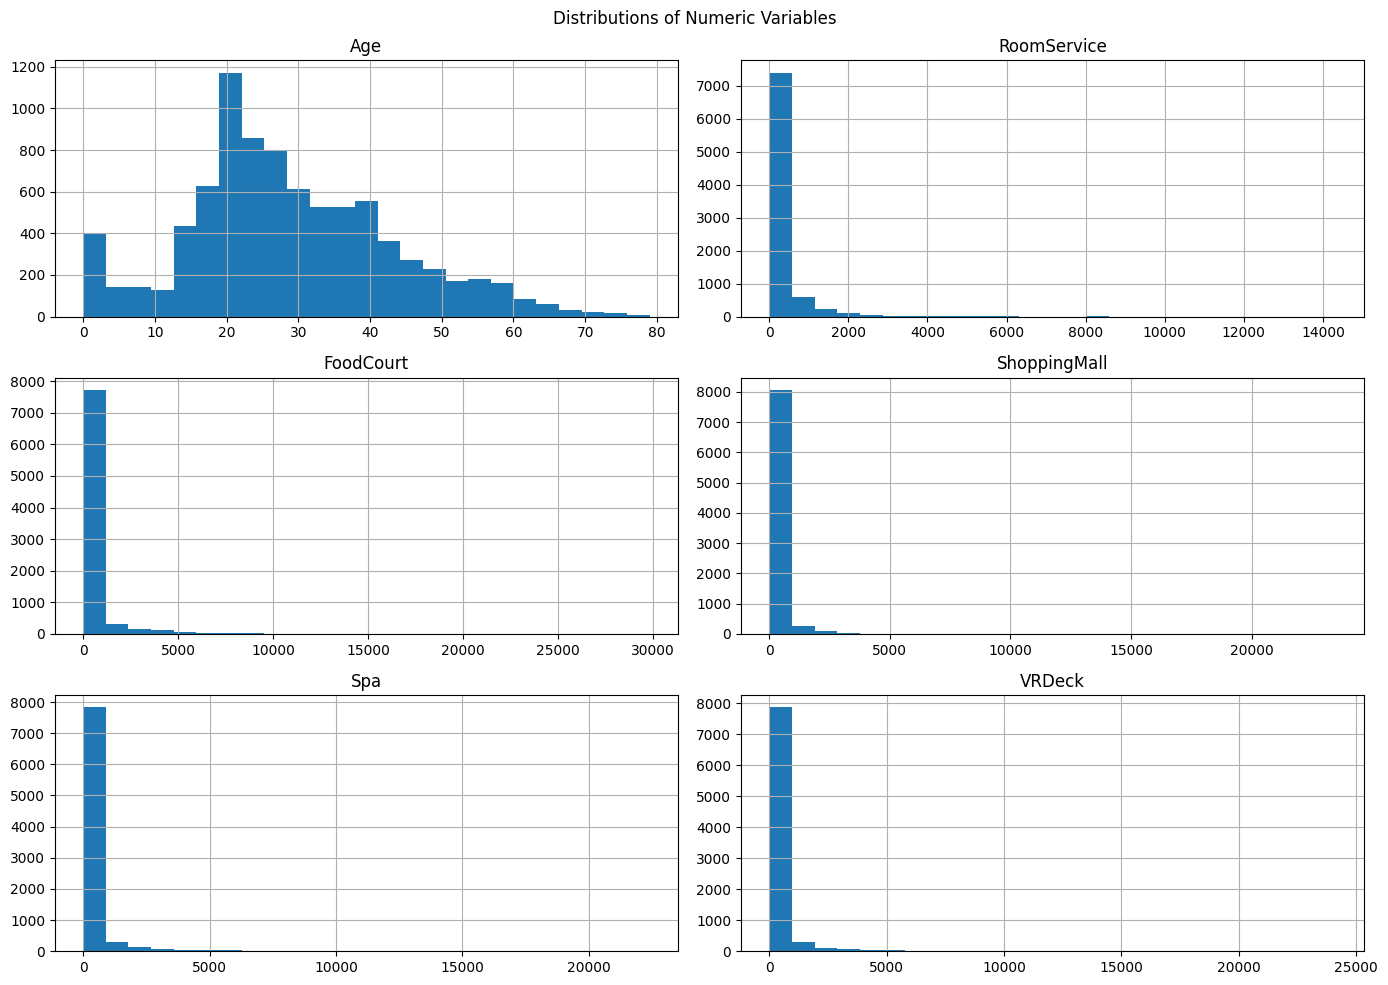

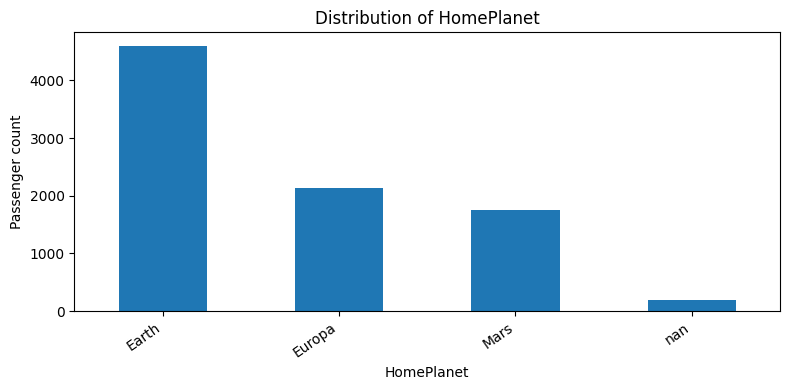

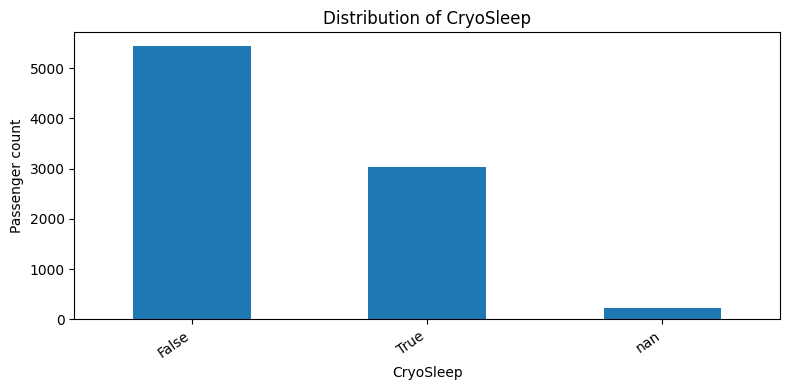

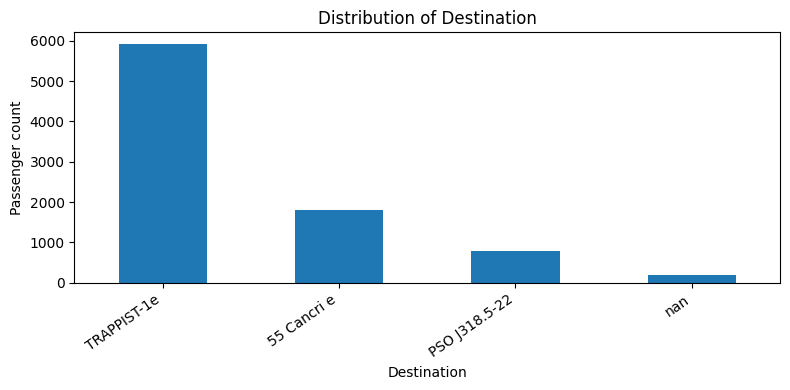

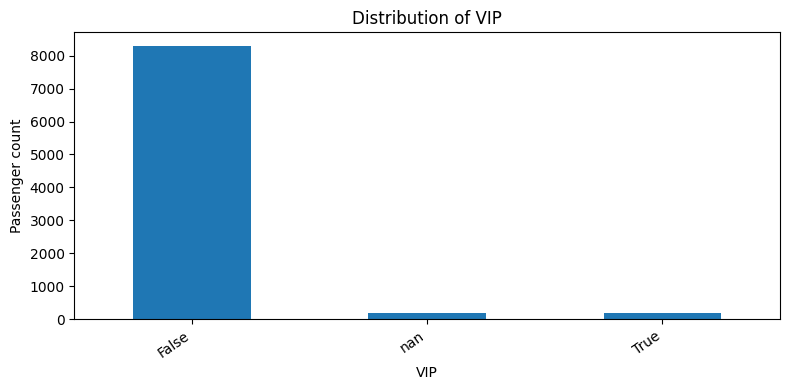

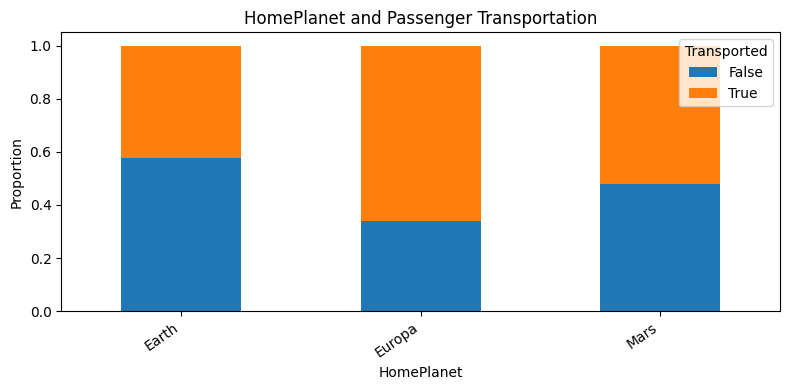

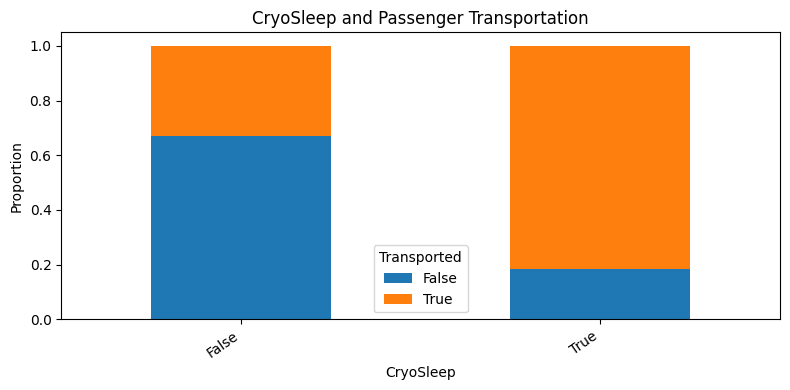

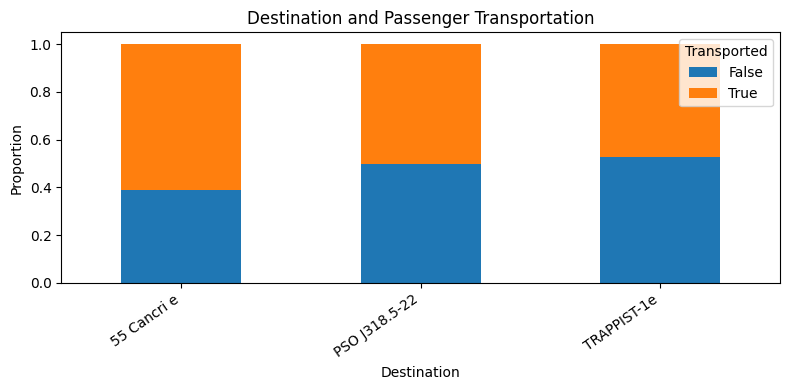

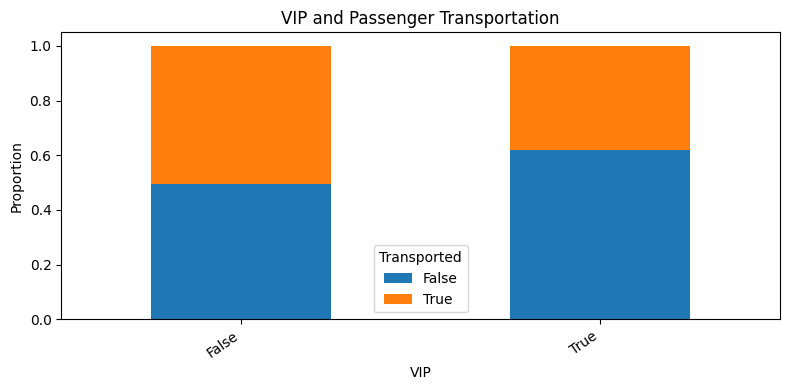

In [6]:
print("\n5. EXPLORATORY DATA ANALYSIS")

numeric_columns = train.select_dtypes(
    include=np.number
).columns.tolist()

numeric_columns = [
    c for c in numeric_columns
    if c not in ["Transported"]
]

train[numeric_columns].hist(
    figsize=(14, 10),
    bins=25
)

plt.suptitle("Distributions of Numeric Variables")
plt.tight_layout()
plt.show()

categorical_columns = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP"
]

for col in categorical_columns:
    plt.figure(figsize=(8, 4))
    train[col].value_counts(dropna=False).plot(kind="bar")
    plt.title(f"Distribution of {col}")
    plt.ylabel("Passenger count")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# Relationship between selected variables and target

for col in ["HomePlanet", "CryoSleep", "Destination", "VIP"]:
    relationship = pd.crosstab(
        train[col],
        train["Transported"],
        normalize="index"
    )

    relationship.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"{col} and Passenger Transportation")
    plt.ylabel("Proportion")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

6. FEATURE ENGINEERING

In [7]:
print("\n6. FEATURE ENGINEERING")

def create_features(data, combined_data):
    df = data.copy()

    # Passenger group size
    group_ids = combined_data["PassengerId"].str.split(
        "_"
    ).str[0]

    group_counts = group_ids.value_counts()

    passenger_groups = df["PassengerId"].str.split(
        "_"
    ).str[0]

    df["GroupSize"] = passenger_groups.map(group_counts)

    # Cabin information
    cabin_parts = df["Cabin"].str.split("/", expand=True)

    df["CabinDeck"] = cabin_parts[0]
    df["CabinNumber"] = pd.to_numeric(
        cabin_parts[1], errors="coerce"
    )
    df["CabinSide"] = cabin_parts[2]

    # Total expenditure
    spending_columns = [
        "RoomService",
        "FoodCourt",
        "ShoppingMall",
        "Spa",
        "VRDeck"
    ]

    df["TotalSpend"] = df[spending_columns].sum(
        axis=1, min_count=1
    )

    df["LogTotalSpend"] = np.log1p(df["TotalSpend"])

    df["AnySpend"] = (
        df["TotalSpend"] > 0
    ).astype(int)

    df["NoSpend"] = (
        df["TotalSpend"] == 0
    ).astype(int)

    # Age categories
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[0, 12, 18, 30, 50, 100],
        labels=[
            "Child",
            "Teenager",
            "Young Adult",
            "Adult",
            "Senior"
        ]
    )

    # Surname frequency
    surname = df["Name"].str.split().str[0]

    combined_surnames = (
        combined_data["Name"].str.split().str[0]
    )

    surname_counts = combined_surnames.value_counts()

    df["SurnameCount"] = surname.map(surname_counts)

    # Remove original high-cardinality or decomposed fields
    df = df.drop(
        columns=[
            "PassengerId",
            "Name",
            "Cabin"
        ],
        errors="ignore"
    )

    return df


combined = pd.concat(
    [train.drop(columns=["Transported"]), test],
    ignore_index=True
)

X = create_features(
    train.drop(columns=["Transported"]),
    combined
)

X_test = create_features(test, combined)

y = train["Transported"].astype(int)

# Convert Boolean columns into categorical text
for col in X.columns:
    if X[col].dtype == "bool":
        X[col] = X[col].astype("object")

for col in X_test.columns:
    if X_test[col].dtype == "bool":
        X_test[col] = X_test[col].astype("object")

print("Engineered training data:", X.shape)
print("Engineered test data:", X_test.shape)

print("\nNEW FEATURES CREATED:")
print(
    "GroupSize, CabinDeck, CabinNumber, CabinSide, "
    "TotalSpend, LogTotalSpend, AnySpend, NoSpend, "
    "AgeGroup and SurnameCount"
)


6. FEATURE ENGINEERING
Engineered training data: (8693, 20)
Engineered test data: (4277, 20)

NEW FEATURES CREATED:
GroupSize, CabinDeck, CabinNumber, CabinSide, TotalSpend, LogTotalSpend, AnySpend, NoSpend, AgeGroup and SurnameCount


7. TRAIN-VALIDATION SPLIT

In [8]:
print("\n7. SPLITTING TRAINING DATA")

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Validation observations:", X_val.shape[0])


7. SPLITTING TRAINING DATA
Training observations: 6954
Validation observations: 1739


8. PREPROCESSING

In [9]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    c for c in X_train.columns
    if c not in numeric_features
]

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("\n8. PREPROCESSING CONFIGURATION")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Numeric: median imputation, missing indicators and scaling.")
print("Categorical: most-frequent imputation and one-hot encoding.")



8. PREPROCESSING CONFIGURATION
Numeric features: ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'GroupSize', 'CabinNumber', 'TotalSpend', 'LogTotalSpend', 'AnySpend', 'NoSpend', 'SurnameCount']
Categorical features: ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'CabinDeck', 'CabinSide', 'AgeGroup']
Numeric: median imputation, missing indicators and scaling.
Categorical: most-frequent imputation and one-hot encoding.


9. BASELINE MODEL

In [10]:
print("\n9. BASELINE MODEL")

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

baseline_accuracy = accuracy_score(
    y_val, baseline_predictions
)

print("Baseline accuracy:", round(baseline_accuracy, 4))


9. BASELINE MODEL
Baseline accuracy: 0.5037


10. TRAIN THREE MACHINE LEARNING MODELS

In [11]:
print("\n10. TRAINING MACHINE LEARNING MODELS")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=22,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

results = []

fitted_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)

    fitted_models[name] = pipeline

    results.append({
        "Model": name,
        "Validation Accuracy": accuracy
    })

    print("Validation accuracy:", round(accuracy, 4))


10. TRAINING MACHINE LEARNING MODELS

Training Logistic Regression...
Validation accuracy: 0.7901

Training Random Forest...
Validation accuracy: 0.8045

Training Gradient Boosting...
Validation accuracy: 0.7907


11. RANDOM FOREST HYPERPARAMETER TUNING

In [12]:
print("\n11. RANDOM FOREST HYPERPARAMETER TUNING")

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

parameter_grid = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 10, 16, 22],
    "model__min_samples_leaf": [1, 2, 3, 4],
    "model__max_features": ["sqrt", 0.8]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    rf_pipeline,
    parameter_grid,
    n_iter=6,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

tuned_predictions = search.best_estimator_.predict(X_val)

tuned_accuracy = accuracy_score(
    y_val, tuned_predictions
)

print("\nBest parameters:")
print(search.best_params_)

print(
    "Best cross-validation accuracy:",
    round(search.best_score_, 4)
)

print(
    "Tuned validation accuracy:",
    round(tuned_accuracy, 4)
)

results.append({
    "Model": "Tuned Random Forest",
    "Validation Accuracy": tuned_accuracy
})


11. RANDOM FOREST HYPERPARAMETER TUNING
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best parameters:
{'model__n_estimators': 400, 'model__min_samples_leaf': 3, 'model__max_features': 'sqrt', 'model__max_depth': 22}
Best cross-validation accuracy: 0.804
Tuned validation accuracy: 0.8028


12. FIVE-FOLD CROSS-VALIDATION

In [13]:
print("\n12. FIVE-FOLD CROSS-VALIDATION")

best_rf = fitted_models["Random Forest"]

five_fold_scores = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="accuracy",
    n_jobs=-1
)

print("Individual fold scores:", five_fold_scores)
print("Mean accuracy:", round(five_fold_scores.mean(), 4))
print("Standard deviation:", round(five_fold_scores.std(), 4))



12. FIVE-FOLD CROSS-VALIDATION
Individual fold scores: [0.8015816  0.80948958 0.79942487 0.7922358  0.80863309]
Mean accuracy: 0.8023
Standard deviation: 0.0064


 13. MODEL COMPARISON

In [14]:
print("\n13. MODEL COMPARISON")

results.append({
    "Model": "Majority Baseline",
    "Validation Accuracy": baseline_accuracy
})

comparison = pd.DataFrame(results).sort_values(
    "Validation Accuracy",
    ascending=False
)

comparison["Validation Accuracy"] = (
    comparison["Validation Accuracy"].round(4)
)

display(comparison)

comparison.to_csv(
    "model_comparison.csv",
    index=False
)



13. MODEL COMPARISON


,Model,Validation Accuracy
1,Random Forest,0.8045
3,Tuned Random Forest,0.8028
2,Gradient Boosting,0.7907
0,Logistic Regression,0.7901
4,Majority Baseline,0.5037


14. FINAL MODEL SELECTION

In [15]:
print("\n14. FINAL MODEL SELECTION")

candidate_models = {
    **fitted_models,
    "Tuned Random Forest": search.best_estimator_
}

best_model_name = max(
    candidate_models,
    key=lambda name: accuracy_score(
        y_val,
        candidate_models[name].predict(X_val)
    )
)

final_model = candidate_models[best_model_name]

print("Selected model:", best_model_name)

final_validation_predictions = final_model.predict(X_val)

print("\nValidation classification report:")
print(
    classification_report(
        y_val,
        final_validation_predictions
    )
)



14. FINAL MODEL SELECTION
Selected model: Random Forest

Validation classification report:
              precision    recall  f1-score   support

           0       0.79      0.82      0.81       863
           1       0.82      0.79      0.80       876

    accuracy                           0.80      1739
   macro avg       0.80      0.80      0.80      1739
weighted avg       0.80      0.80      0.80      1739



15. TRAIN FINAL MODEL ON ALL AVAILABLE TRAINING DATA

In [16]:
print("\n15. FITTING FINAL MODEL")

final_model.fit(X, y)

test_predictions = final_model.predict(X_test)


15. FITTING FINAL MODEL


16. CREATE KAGGLE SUBMISSION

In [17]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Transported": test_predictions.astype(bool)
})

submission.to_csv(
    "submission.csv",
    index=False
)

print("\n16. KAGGLE SUBMISSION CREATED")

display(submission.head())

print("Submission rows:", len(submission))
print("Submission columns:", submission.columns.tolist())
print("Missing predictions:", submission["Transported"].isnull().sum())

assert len(submission) == len(test)
assert submission["PassengerId"].equals(test["PassengerId"])
assert submission["Transported"].notnull().all()


16. KAGGLE SUBMISSION CREATED


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


Submission rows: 4277
Submission columns: ['PassengerId', 'Transported']
Missing predictions: 0


17. DOWNLOADABLE PROJECT OUTPUTS

In [18]:
print("\n17. SAVED OUTPUT FILES")

print("submission.csv")
print("model_comparison.csv")

print("\n" + "=" * 65)
print("ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 65)



17. SAVED OUTPUT FILES
submission.csv
model_comparison.csv

ANALYSIS COMPLETED SUCCESSFULLY
